# SQANTI categories of transcripts and proteins

One objective: count how many of the isoforms are known (FSM), truncated known (ISM), or novel (NIC, NNC), for the transcripts and for the proteins predicted from them.

In [1]:
source("src/classification.R")
options(repr.plot.width = 8, repr.plot.height = 5)
results_dir <- "../LRP2_test_results"   # change to the results folder of the run
dataset_name <- "SERVES_LRP2_test"       # prefix of the S3 files
cls <- read_classification(file.path(results_dir, paste0(dataset_name, ".predicted_proteome.best_ORF_SQANTI_classification.tsv")))
nrow(cls)

[1] 300

**Explanation.** Same idea as the other notebooks: two lines to change for another run. The table has one row per isoform with the best predicted protein; the number above is how many.

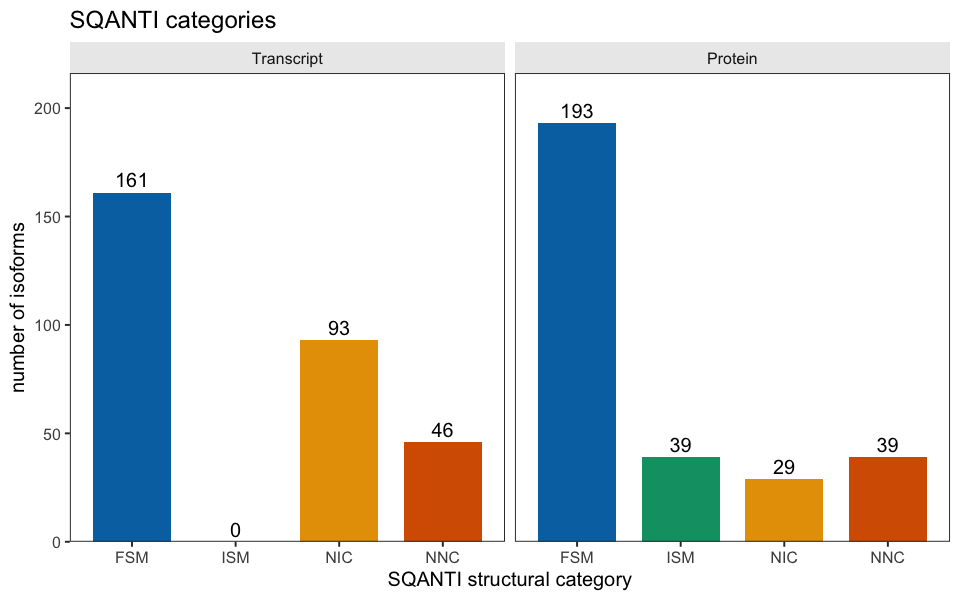

In [2]:
class_barplot(class_counts(cls), title = "SQANTI categories")

**Explanation.** FSM (full splice match): the same splice junctions as a reference. ISM (incomplete splice match): a truncated version of a reference. NIC (novel in catalog): known splice sites combined in a new way. NNC (novel not in catalog): at least one new splice site. The left panel is the transcripts; the right panel is the proteins predicted from them, which can fall in a different category than their transcript.

In [3]:
class_crosstab(cls)

          protein
transcript FSM ISM NIC NNC
       FSM 146  10   2   3
       ISM   0   0   0   0
       NIC  34  26  26   7
       NNC  13   3   1  29

**Explanation.** Each row is a transcript category and each column the category of its protein. A novel transcript (NIC or NNC) in the FSM column makes a protein that is already known, so the new splicing does not change the protein.